Text as live characters: styled ranges, per-glyph moves and rotations, outlines and cut-outs.

Run it as ``python typography.py [OUTPUT_DIR]`` or open ``typography.ipynb`` to see each step.

In [1]:
import math
import sys
import tempfile
from pathlib import Path

import svgwriter as svg

Text stays text. Slicing a `Text` selects a character range that can be wrapped in a styled `<tspan>`.

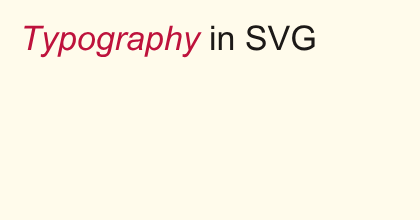

In [2]:
WIDTH, HEIGHT = 420, 220
SERIF = "Georgia, Times New Roman, serif"
SANS = "Arial, Helvetica, sans-serif"

doc = svg.Document(WIDTH, HEIGHT)
doc.style("text { font-family: Arial, Helvetica, sans-serif; } .accent { fill: #be123c; }")
doc.rect(0, 0, WIDTH, HEIGHT, fill="#fffbeb")

title = doc.text("Typography in SVG", x=20, y=50, font_size=34, font_family=SERIF, fill="#1c1917")
title[0:10].wrap(class_="accent", font_style="italic")
doc

Iterating a `Text` yields its characters, so each can move on its own; a slice rotates as a group.

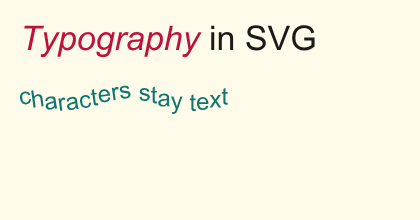

In [3]:
wave = doc.text("characters stay text", x=20, y=105, font_size=24, fill="#0f766e")
for index, glyph in enumerate(wave):
    glyph.translate(0, 6 * math.sin(index / 2))
wave[0:10].rotate(-8)
doc

Subtracting text from a shape cuts the letters out of it, as a stencil.

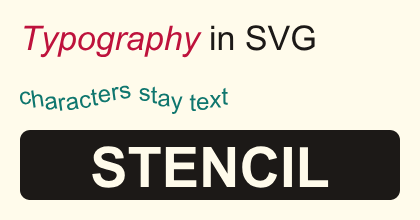

In [4]:
stencil = svg.rect(20, 130, 380, 70, rx=10) - svg.text("STENCIL", x=210, y=187, font_size=56,
                                                      font_family=SANS, font_weight="bold",
                                                      text_anchor="middle")
doc += stencil.update(fill="#1c1917")
doc

`glyphs()` converts text to one outline path per character, which then scale like any shape.

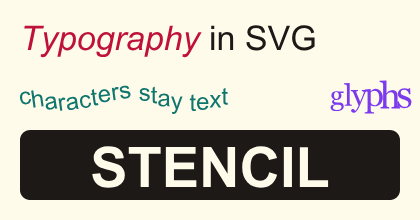

In [5]:
outlines = svg.text("glyphs", x=330, y=105, font_size=28, font_family=SERIF).glyphs()
for index, path in enumerate(outlines):
    path.update(fill="#7c3aed").scale(1 + index * 0.08)
doc += outlines
doc

Save SVG and a 2x PNG. Pass a folder as the first argument to choose where they go.

In [6]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "typography.svg")
doc.save(out / "typography.png", scale=2)
print("saved typography.svg and typography.png")

saved typography.svg and typography.png
